In [1]:
import os
print(os.getcwd())
print(os.listdir("."))

c:\Users\david\OneDrive\Documentos\GitHub\Project-1-CAD
['.git', '.gitignore', '.idea', '.python-version', '.venv', '.venv-old', 'dataset', 'features_1', 'ml-results', 'models', 'notebooks', 'pyproject.toml', 'src', 'train', 'train (1)', 'uv.lock', 'val', 'val (1)']


In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from PIL import Image
from src.config import *
import numpy as np
from src.utils import *

import pandas as pd
from PIL import Image
from src.config import *
import numpy as np
from src.utils import *

In [3]:
LABEL_MAP = {"nevus": 0, "others": 1}

records = []
for folder, label in LABEL_MAP.items():
    for img_path in sorted((BINARY_TRAIN_DIR / folder).glob("*.jpg")):
        with Image.open(img_path) as img:
            records.append({
                "filename": img_path.name,
                "class": folder,
                "label": label,
                "subtype": img_path.stem.rstrip("0123456789"),  # e.g. 'nev', 'ack', 'bcc'
                "width": img.width,
                "height": img.height,
            })

meta_data = pd.DataFrame(records)
meta_data.head()

,filename,class,label,subtype,width,height
0,nev00001.jpg,nevus,0,nev,600,450
1,nev00002.jpg,nevus,0,nev,1024,1024
2,nev00003.jpg,nevus,0,nev,1024,1024
3,nev00004.jpg,nevus,0,nev,600,450
4,nev00005.jpg,nevus,0,nev,600,450


In [4]:
print("Class counts:\n", meta_data["class"].value_counts(), "\n")

meta_data["size"] = meta_data["width"].astype(str) + "x" + meta_data["height"].astype(str)
print("Number of distinct sizes:", meta_data["size"].nunique())
print(meta_data["size"].value_counts().head(10), "\n")

print(meta_data[["width", "height"]].describe())

Class counts:
 class
nevus     7725
others    7470
Name: count, dtype: int64 

Number of distinct sizes: 73
size
1024x1024    7452
600x450      6024
1024x680      681
1024x768      462
1024x682       99
1024x685       93
1024x681       47
1024x764       44
1024x679       34
919x802        33
Name: count, dtype: int64 

              width        height
count  15195.000000  15195.000000
mean     854.632971    760.666206
std      207.044048    269.914304
min      576.000000    450.000000
25%      600.000000    450.000000
50%     1024.000000    768.000000
75%     1024.000000   1024.000000
max     1024.000000   1024.000000


In [5]:
gt = meta_data[["filename", "label"]]
gt.to_csv(BINARY_GT_TRAIN_CSV, index=False)
print(f"Saved {len(gt)} rows to {BINARY_GT_TRAIN_CSV}")

Saved 15195 rows to C:\Users\david\OneDrive\Documentos\GitHub\Project-1-CAD\dataset\binary\train_ground_truth.csv


In [6]:
pd.crosstab(meta_data["size"], meta_data["class"]).sort_values("nevus", ascending=False).head(10)

class,nevus,others
size,,
600x450,4045,1979
1024x1024,2519,4933
1024x680,411,270
1024x768,351,111
1024x682,87,12
1024x685,58,35
1024x681,35,12
767x576,27,6
1024x679,25,9


seed: 166


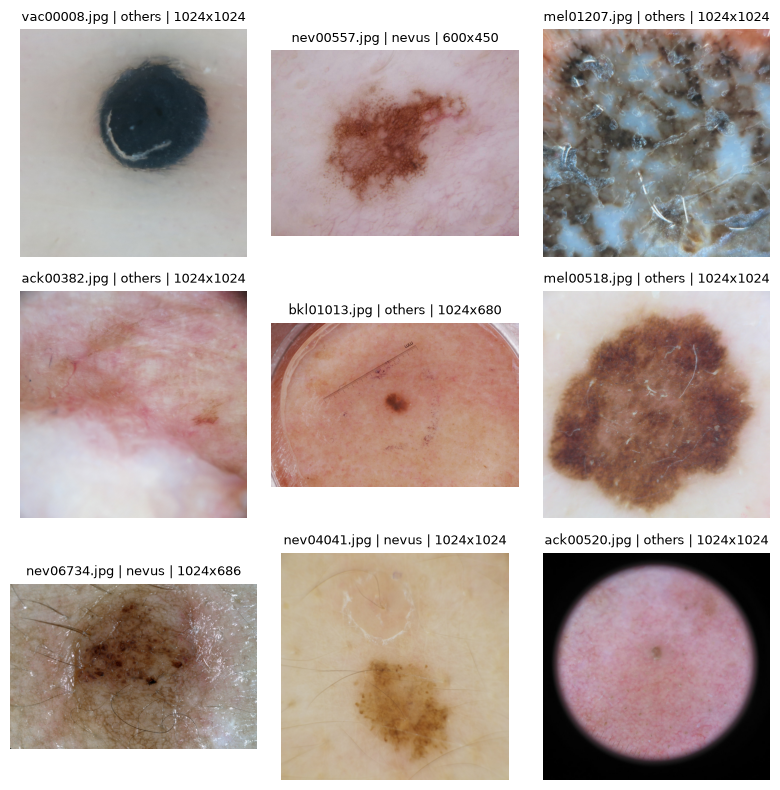

In [7]:
seed = np.random.randint(0, 1000)
print("seed:", seed)

sample = meta_data.sample(9, random_state=seed)

images, titles = [], []
for _, row in sample.iterrows():
    img = Image.open(BINARY_TRAIN_DIR / row["class"] / row["filename"])
    images.append(np.array(img))
    titles.append(f'{row["filename"]} | {row["class"]} | {row["width"]}x{row["height"]}')

show_grid(images, titles)